In [3]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import plotly_express as px
import pandas_datareader as web
from datetime import datetime as dt, timedelta as td
import finpy_tse as fp
import warnings

In [ ]:
stocks = ['دکپسول', 'فولاد', 'ثشرق', 'سپیدار', 'سصوفی', 'تپسی']
mydata = pd.DataFrame()
warnings.filterwarnings("ignore", category=FutureWarning)
for stock in stocks:
    mydata[stock] = fp.Get_Price_History(stock,start_date='1399-01-01',end_date='1402-12-29',ignore_date=False,adjust_price=True
                                     ,show_weekday=False,double_date=False)['Close']

NameError: name 'warnings' is not defined

In [ ]:
mydata
# mydata.dropna(inplace=True)
px.line(mydata * 100 / mydata.iloc[0])
ret_port = mydata.pct_change()
px.line(ret_port)

C:\Users\User\AppData\Local\Temp\ipykernel_17016\2528016099.py:4: FutureWarning:

The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.



In [ ]:
np.random.seed(1)
# Weight each security
weights = np.random.random((6,1))
# normalize it, so that some is one
weights /= np.sum(weights)
print(f'Normalized Weights : {weights.flatten()}')

# We generally do log return instead of return
log_ret = np.log(mydata / mydata.shift(1))
log_ret

# Expected return (weighted sum of mean returns). Mult by 252 as we always do annual calculation and year has 252 business days
exp_ret = log_ret.mean().dot(weights)*252 
print(f'\nExpected return of the portfolio is : {exp_ret[0]}')

# Exp Volatility (Risk)
exp_vol = np.sqrt(weights.T.dot(252*log_ret.cov().dot(weights)))
print(f'\nVolatility of the portfolio: {exp_vol[0][0]}')

# Sharpe ratio
sr = exp_ret / exp_vol
print(f'\nSharpe ratio of the portfolio: {sr[0][0]}')

Normalized Weights : [2.48391806e-01 4.29048586e-01 6.81253437e-05 1.80079067e-01
 8.74125593e-02 5.49998562e-02]

Expected return of the portfolio is : 0.5030448777124548

Volatility of the portfolio: 0.2822237363436215

Sharpe ratio of the portfolio: 1.7824329173360969


In [7]:
# number of simulation
n = 50_000
# n = 10

port_weights = np.zeros(shape=(n,len(mydata.columns)))
port_volatility = np.zeros(n)
port_sr = np.zeros(n)
port_return = np.zeros(n)

num_securities = len(mydata.columns)
# num_securities
for i in range(n):
    # Weight each security
    weights = np.random.random(6)
    # normalize it, so that some is one
    weights /= np.sum(weights)
    port_weights[i,:] = weights 
    #     print(f'Normalized Weights : {weights.flatten()}')

    # Expected return (weighted sum of mean returns). Mult by 252 as we always do annual calculation and year has 252 business days
    exp_ret = log_ret.mean().dot(weights)*252 
    port_return[i] = exp_ret
#     print(f'\nExpected return is : {exp_ret[0]}')

    # Exp Volatility (Risk)
    exp_vol = np.sqrt(weights.T.dot(252*log_ret.cov().dot(weights)))
    port_volatility[i] = exp_vol
#     print(f'\nVolatility : {exp_vol[0][0]}')

    # Sharpe ratio
    sr = exp_ret / exp_vol
    port_sr[i] = sr
#     print(f'\nSharpe ratio : {sr[0][0]}')

In [12]:
# Index of max Sharpe Ratio
max_sr = port_sr.max()
ind = port_sr.argmax()
# Return and Volatility at Max SR
max_sr_ret = port_return[ind]
max_sr_vol = port_volatility[ind]
sr_rat = max_sr_ret/max_sr_vol
sr_rat

np.float64(2.189123016188529)

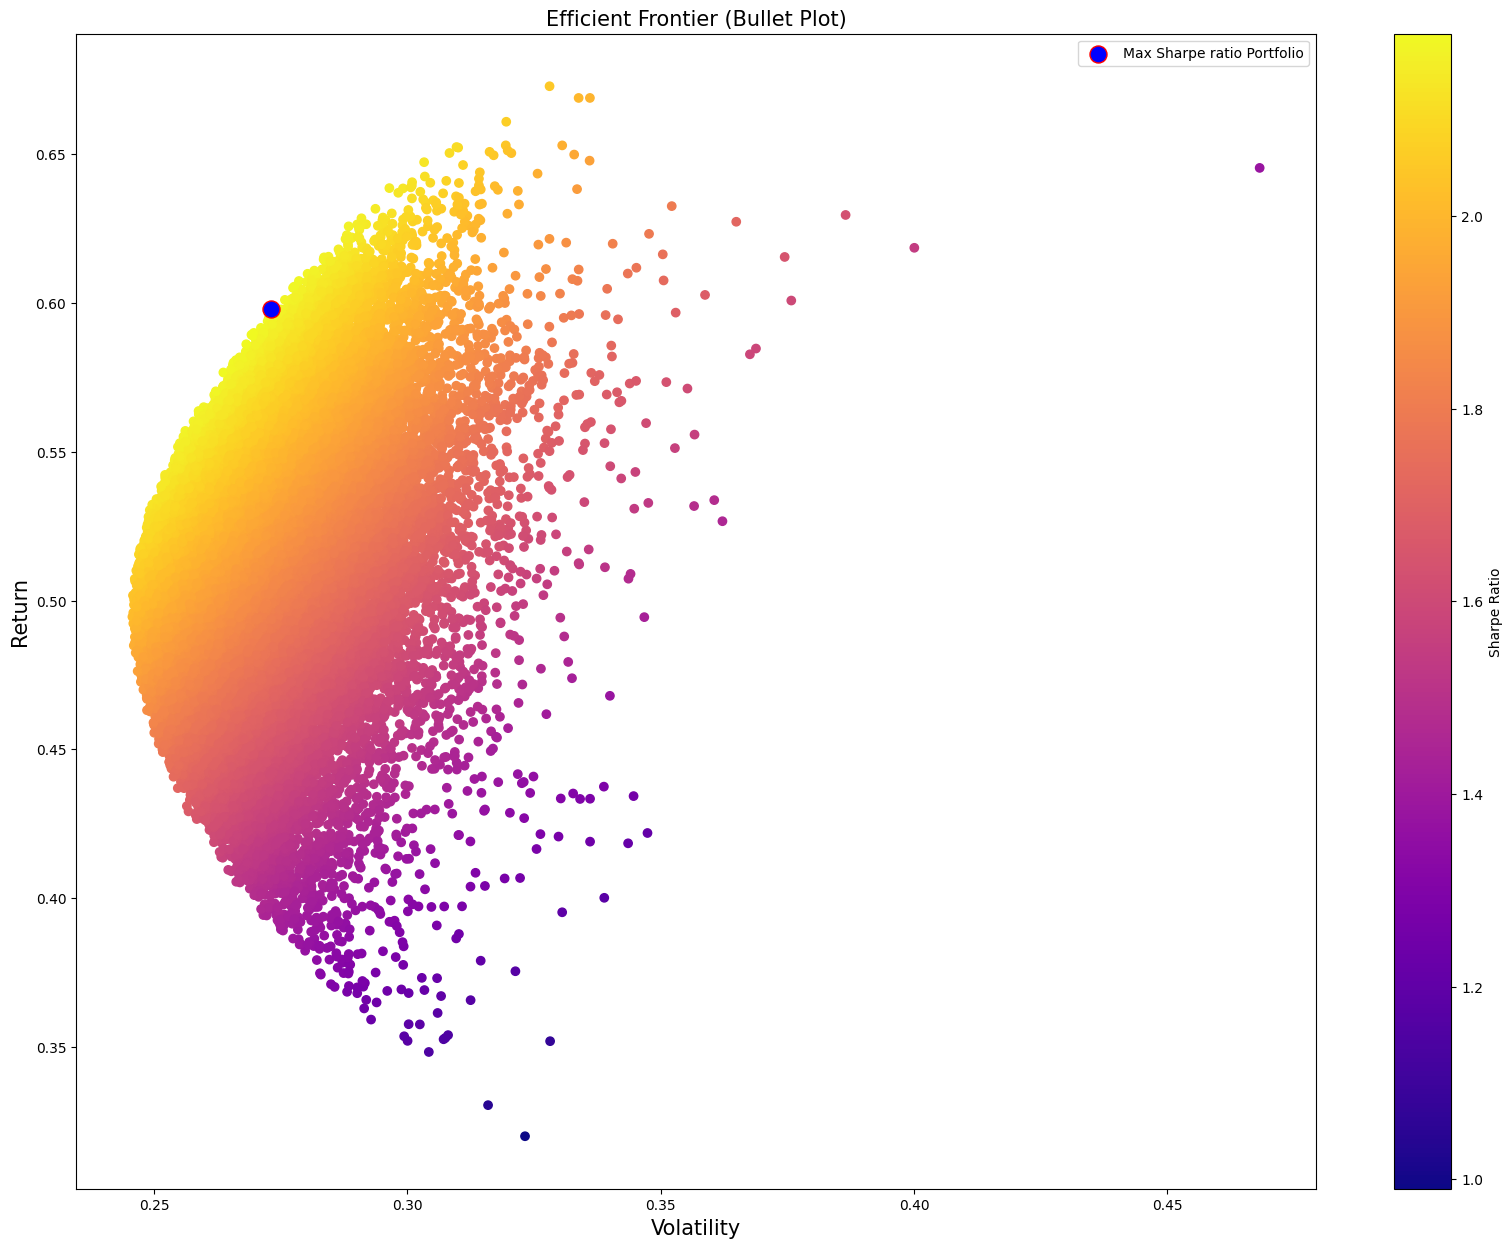

In [13]:
plt.figure(figsize=(20,15))
plt.scatter(port_volatility,port_return,c=port_sr, cmap='plasma')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility', fontsize=15)
plt.ylabel('Return', fontsize=15)
plt.title('Efficient Frontier (Bullet Plot)', fontsize=15)
plt.scatter(max_sr_vol, max_sr_ret, c='blue', s=150, edgecolors='red', marker='o', label='Max \
Sharpe ratio Portfolio')
plt.legend();

In [15]:
for weight, stock in zip(port_weights[ind],stocks):
    print(f'{round(weight * 100, 2)} % of {stock} should be bought.')
    
# best portfolio return
print(f'\nMarkowitz optimal portfolio return is : {round(max_sr_ret * 100, 2)}% with volatility \
{max_sr_vol}') 

3.58 % of دکپسول should be bought.
18.59 % of فولاد should be bought.
22.77 % of ثشرق should be bought.
39.26 % of سپیدار should be bought.
4.79 % of سصوفی should be bought.
11.01 % of تپسی should be bought.

Markowitz optimal portfolio return is : 59.79% with volatility 0.27314478174542695


In [16]:
from scipy import optimize

In [17]:
log_mean = log_ret.mean() * 252
cov = log_ret.cov() * 252

In [18]:
# Some helper functions
def get_ret_vol_sr(weights):
    weights = np.array(weights)
    ret = log_mean.dot(weights)
    vol = np.sqrt(weights.T.dot(cov.dot(weights)))
    sr = ret / vol
    return np.array([ret, vol, sr])

# Negate Sharpe ratio as we need to max it but Scipy minimize the given function
def neg_sr(weights):
    return get_ret_vol_sr(weights)[-1] * -1

# check sum of weights 
def check_sum(weights):
    return np.sum(weights) - 1

# Constraints for the optimization problem
cons = {'type':'eq','fun':check_sum}
# bounds on weights
bounds = ((0,1),(0,1),(0,1),(0,1),(0,1),(0,1))
# initial guess for optimization to start with
init_guess = [.25 for _ in range(6)]


# Call minimizer
opt_results = optimize.minimize(neg_sr, init_guess, constraints=cons, bounds=bounds, method='SLSQP')

In [19]:
optimal_weights = opt_results.x
# optimal_weights
for st, i in zip(stocks,optimal_weights):
    print(f'Stock {st} has weight {np.round(i*100,2)} %')

Stock دکپسول has weight 6.26 %
Stock فولاد has weight 18.67 %
Stock ثشرق has weight 20.5 %
Stock سپیدار has weight 37.12 %
Stock سصوفی has weight 6.98 %
Stock تپسی has weight 10.47 %


In [20]:
mc_weights = port_weights[ind]
for st, i in zip(stocks,mc_weights):
    print(f'Stock {st} has weight {np.round(i*100,2)} %')

Stock دکپسول has weight 3.58 %
Stock فولاد has weight 18.59 %
Stock ثشرق has weight 22.77 %
Stock سپیدار has weight 39.26 %
Stock سصوفی has weight 4.79 %
Stock تپسی has weight 11.01 %


In [21]:
# Comparing two results we see that we get very close results
(optimal_weights - mc_weights)

array([ 0.02685311,  0.00078183, -0.02269132, -0.02141   ,  0.02186547,
       -0.00539908])

In [36]:
get_ret_vol_sr(optimal_weights), get_ret_vol_sr(mc_weights)

print('For a given portfolio we have: (Using SciPy optimizer)\n \n')
for i, j in enumerate('Return Volatility SharpeRatio'.split()):
    print(f'{j} is : {get_ret_vol_sr(optimal_weights)[i]}\n')
    
print('For a given portfolio we have: (Using Monte Carlo)\n \n')
for i, j in enumerate('Return Volatility SharpeRatio'.split()):
    print(f'{j} is : {get_ret_vol_sr(mc_weights)[i]}\n')

ret1 = get_ret_vol_sr(optimal_weights)[0]
vol1 = get_ret_vol_sr(optimal_weights)[1]

For a given portfolio we have: (Using SciPy optimizer)
 

Return is : 0.5873275878504208

Volatility is : 0.2676590750503938

SharpeRatio is : 2.1943122524048215

For a given portfolio we have: (Using Monte Carlo)
 

Return is : 0.5979475284707066

Volatility is : 0.27314478174542695

SharpeRatio is : 2.1891230161885296



In [37]:
frontier_y = np.linspace(port_return.min(), port_return.max(), 100)
frontier_vol = []

def minimize_vol(weights):
    return get_ret_vol_sr(weights)[1]

for possible_ret in frontier_y:
    cons = ({'type':'eq','fun':check_sum},
            {'type':'eq','fun':lambda w:get_ret_vol_sr(w)[0] - possible_ret})
    result = optimize.minimize(minimize_vol, init_guess, method='SLSQP', constraints=cons, bounds=bounds)
    frontier_vol.append(result['fun'])    

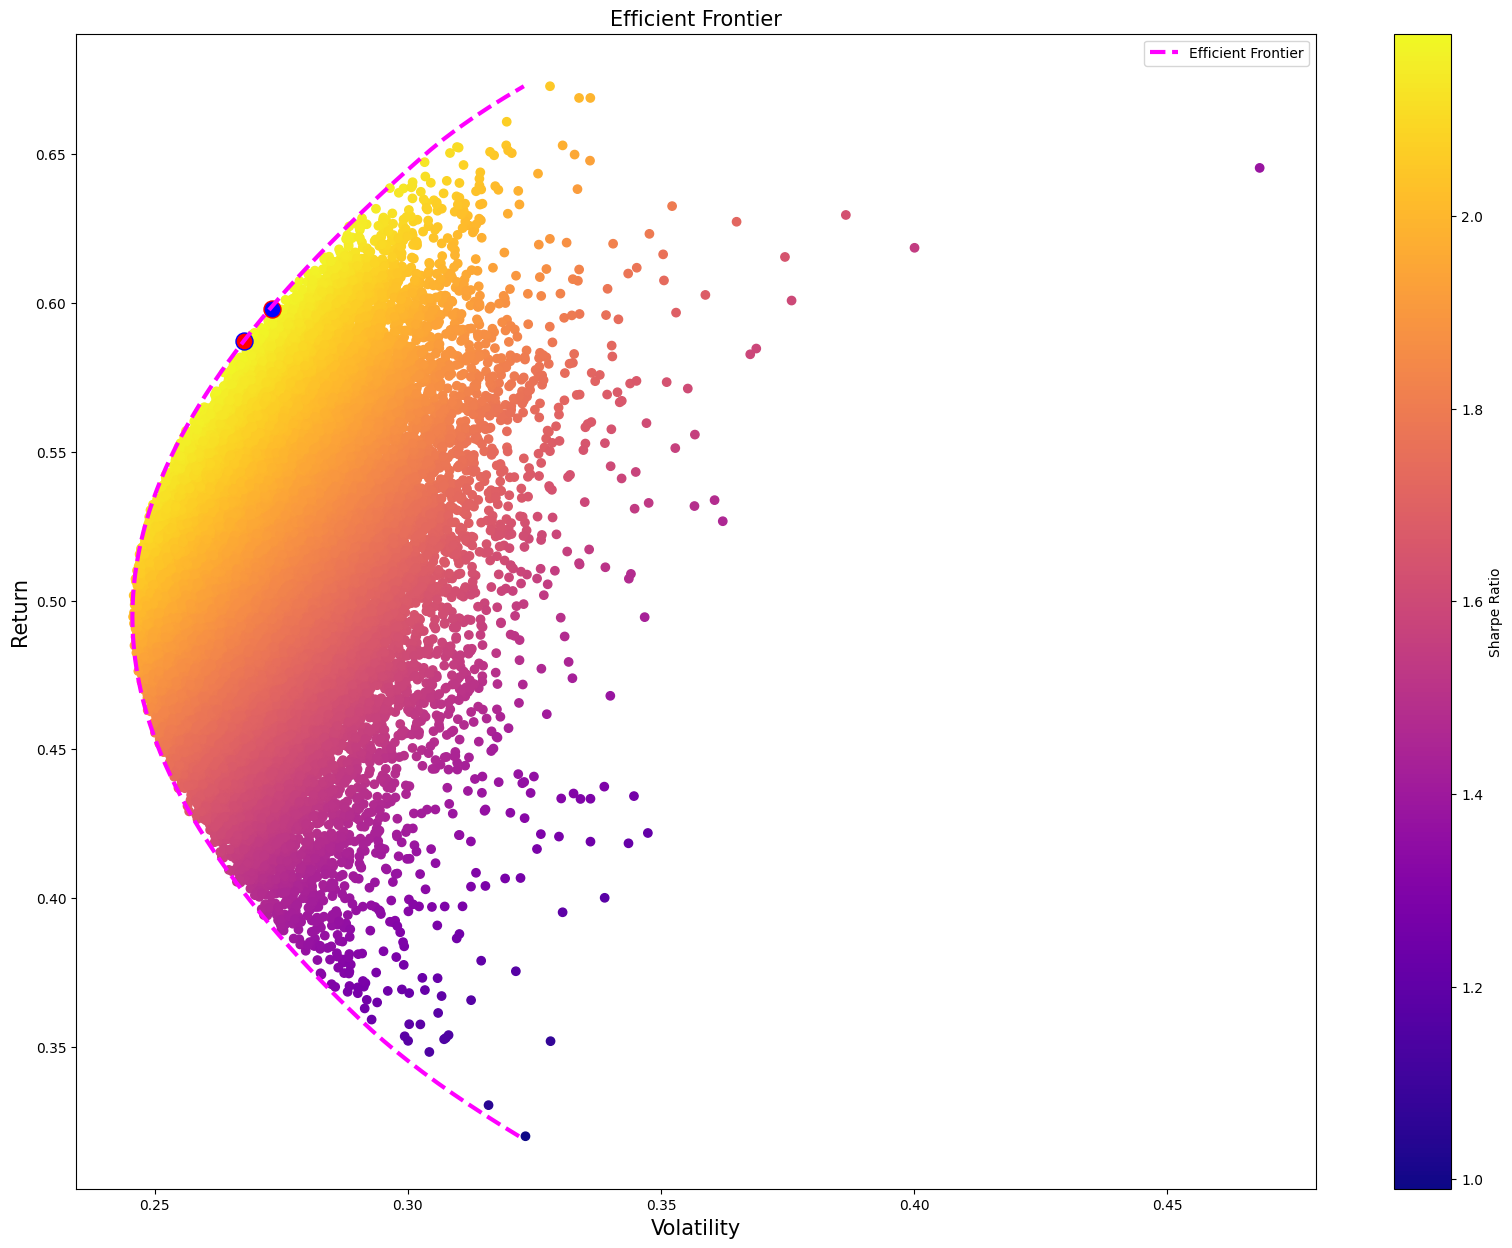

In [40]:
plt.figure(figsize=(20,15))
plt.scatter(port_volatility,port_return,c=port_sr, cmap='plasma')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility', fontsize=15)
plt.ylabel('Return', fontsize=15)
plt.title('Efficient Frontier', fontsize=15)
plt.scatter(max_sr_vol, max_sr_ret, c='blue', s=150, edgecolors='red', marker='o')
plt.scatter(vol1, ret1, c='red', s=150, edgecolors='blue', marker='o')

plt.plot(frontier_vol, frontier_y, c='magenta', ls='--', lw=3, label='Efficient Frontier')
plt.legend();